In [1]:
import pandas as pd
statdata = pd.read_csv('./data/statdata.csv')
statdata.head()

,cpu_time,feature_index,feature_rank,ranking_method,adapter,directory,path,replica_no,replicas,description,name,p,n,p_informative,n_positives,n_true_positives,n_false_positives,n_false_negatives,recall,precision
0,0.150781,17,1.0,ExtraTrees,rebate,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,1,24,"1 Main Effect [p=20,n=1600,h=0.05,edm=Easy]",1 Main Effect,20,1600,19,1,0,1,1,0.0,0.000000
1,0.150781,11,2.0,ExtraTrees,rebate,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,1,24,"1 Main Effect [p=20,n=1600,h=0.05,edm=Easy]",1 Main Effect,20,1600,19,2,0,2,1,0.0,0.000000
2,0.150781,19,3.0,ExtraTrees,rebate,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,1,24,"1 Main Effect [p=20,n=1600,h=0.05,edm=Easy]",1 Main Effect,20,1600,19,3,1,2,0,1.0,0.333333
3,0.150781,13,4.0,ExtraTrees,rebate,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,1,24,"1 Main Effect [p=20,n=1600,h=0.05,edm=Easy]",1 Main Effect,20,1600,19,4,1,3,0,1.0,0.250000
4,0.150781,6,5.0,ExtraTrees,rebate,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,./data/rebate/GAMETES_2.2_dev_peter_mainEff_Da...,1,24,"1 Main Effect [p=20,n=1600,h=0.05,edm=Easy]",1 Main Effect,20,1600,19,5,1,4,0,1.0,0.200000


(157038, 20)


Text(0.5, 1.0, 'recall per ranking method for all datasets')

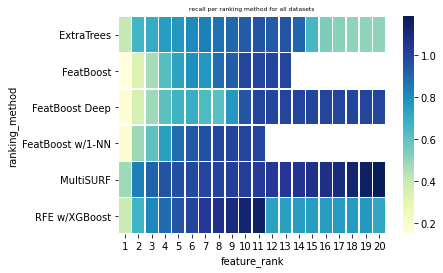

In [17]:
print(statdata.shape)
descr = '1 Main Effect [p=20,n=1600,h=0.05,edm=Easy]'
subset = statdata
# subset = subset[subset['description'] == descr]
subset = subset[subset['feature_rank'] <= 20]
subset = subset[subset['ranking_method'] != 'Stability Selection']

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
rectangular = pd.pivot_table(subset,\
    values='recall',\
    index=['ranking_method'],\
    columns=['feature_rank'])
g = sns.heatmap(rectangular,\
    linewidths=.5, cmap="YlGnBu")
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
plt.title('recall per ranking method for {}'.format(
    'all datasets'
    # descr\
    ))

Construct a sensible subset for plotting

In [55]:
subset = statdata.copy()
for dataset, data in statdata.groupby('description'):
    all_replicas = data.groupby('replica_no')
    if len(all_replicas.count()) != 24: # only 'finished' datasets
        subset = subset[subset['description'] != dataset]
    else: # add newline in plot title
        descr = dataset.replace(' [p=', '\n[p=')
        descr = descr.replace(',h=', ',\nh=')
        subset = subset.replace({ 'description': dataset }, descr)
        # short_descr = '[p=' + dataset.split(' [p=')[1]
        # entries = subset[subset['description'] == dataset]
        # subset.loc[entries.index, 'short_descr'] = short_descr
subset = subset[subset['feature_rank'] <= 20]
subset = subset[subset['ranking_method'] != 'Stability Selection']
subset.shape

(89214, 20)

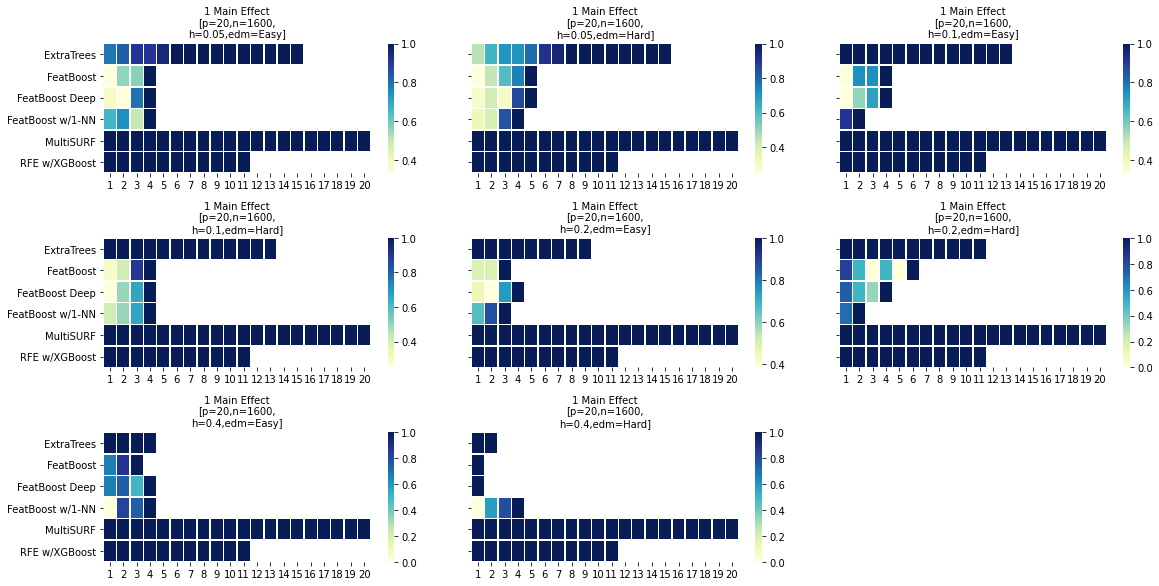

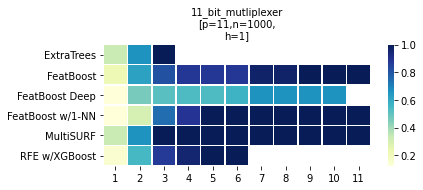

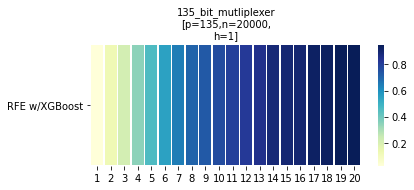

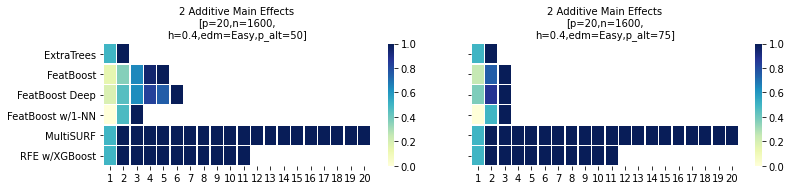

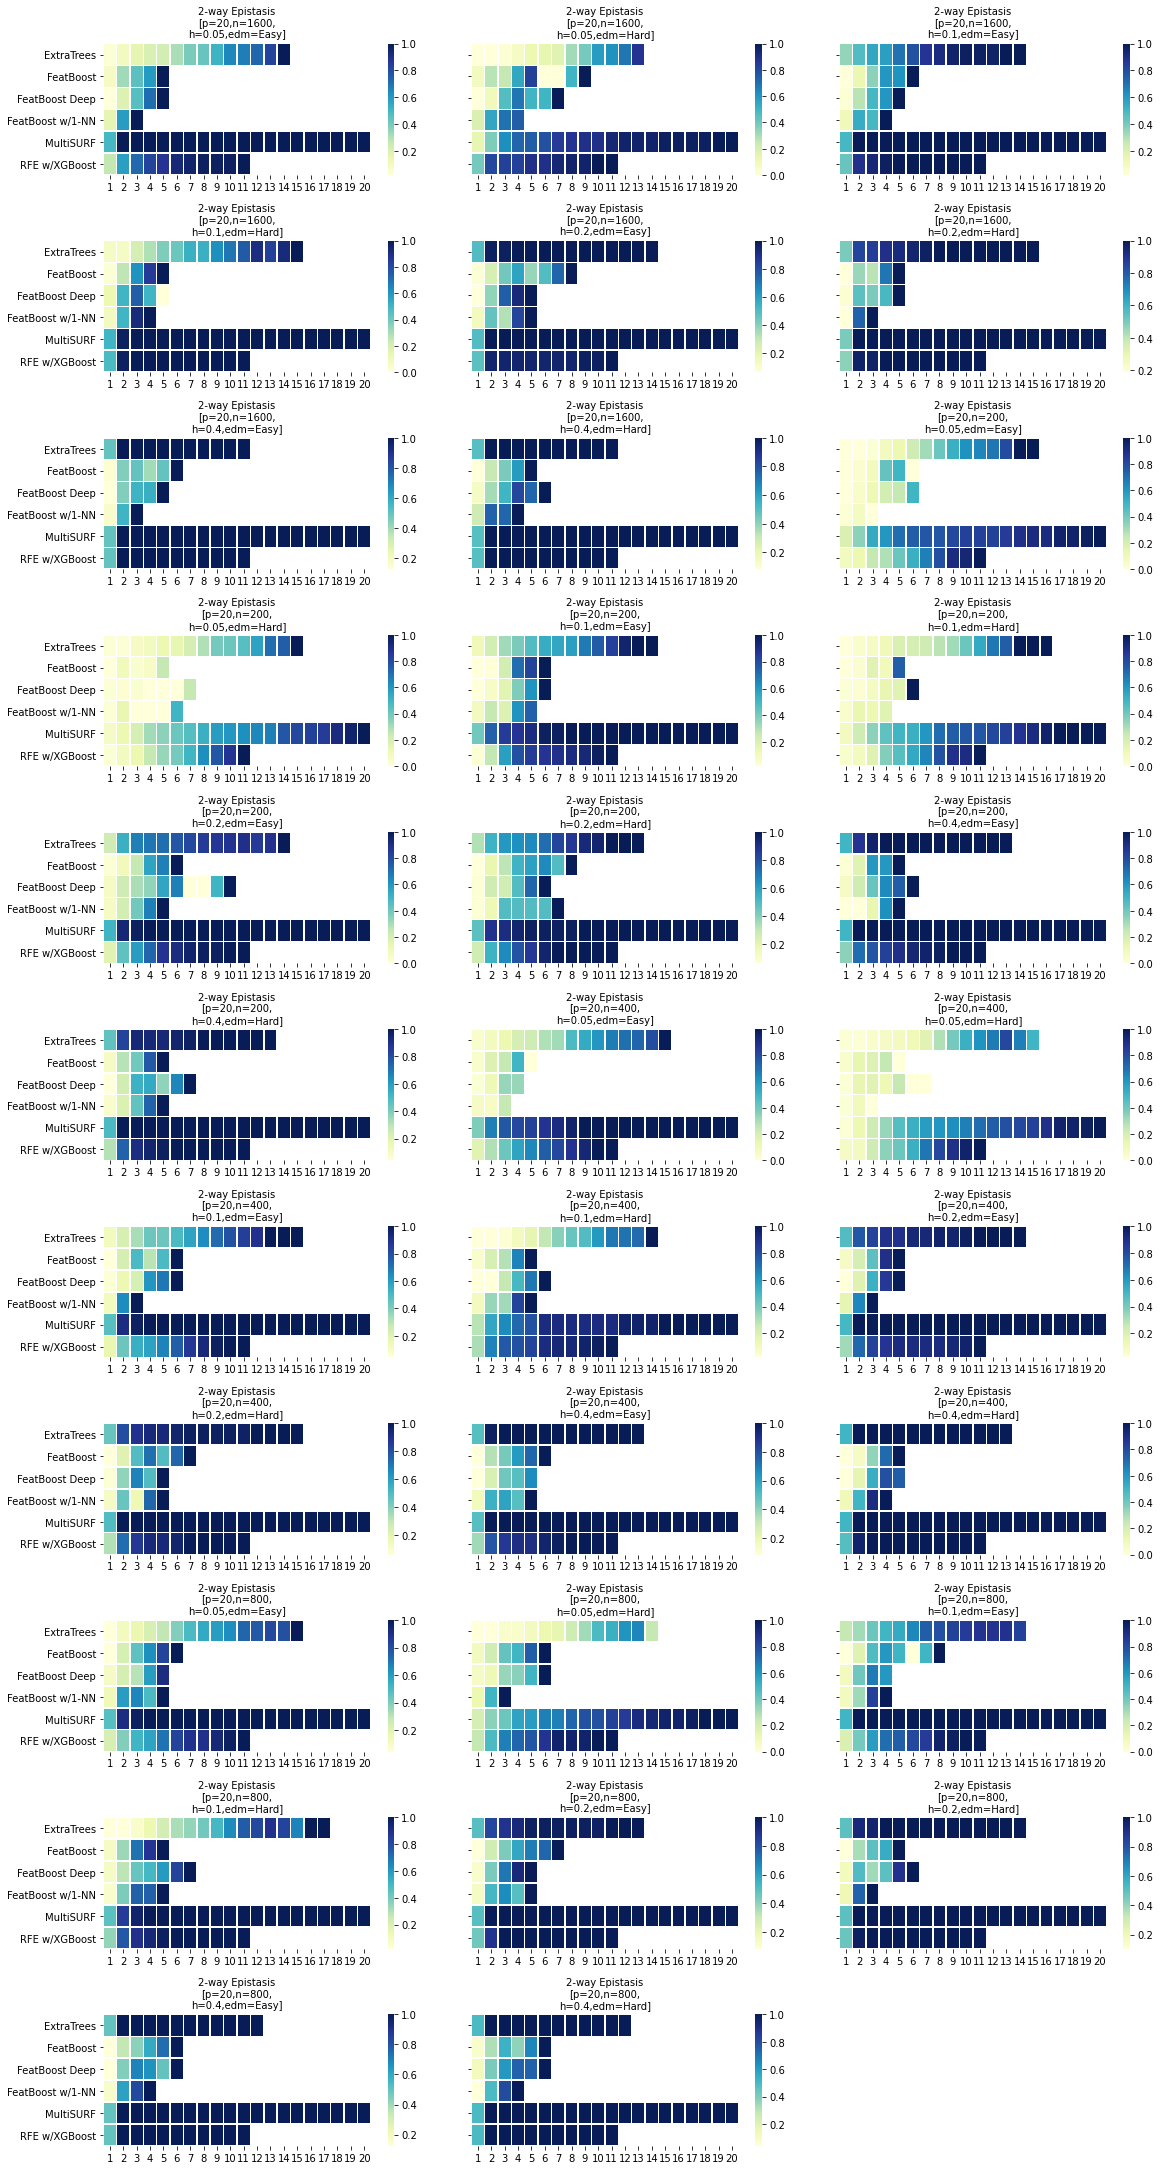

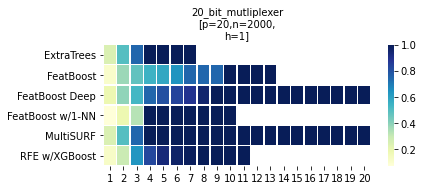

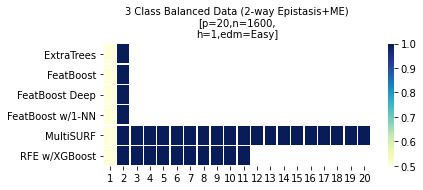

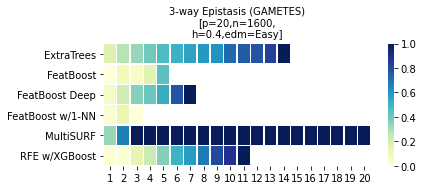

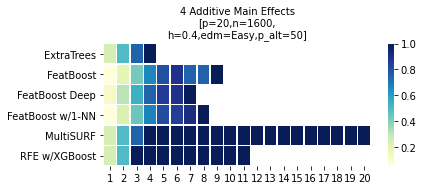

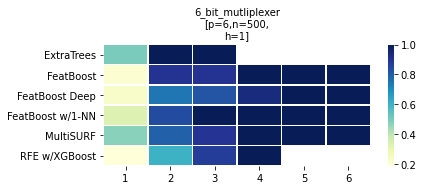

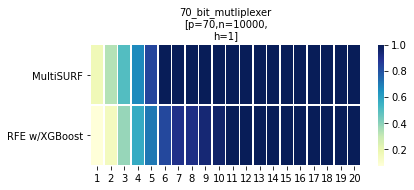

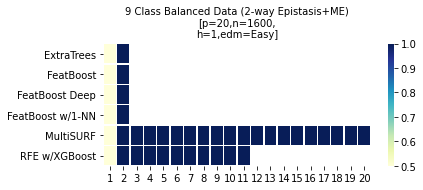

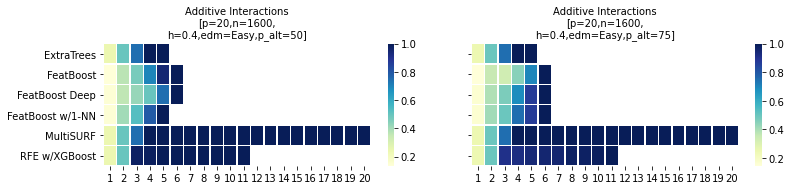

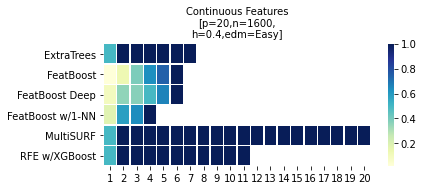

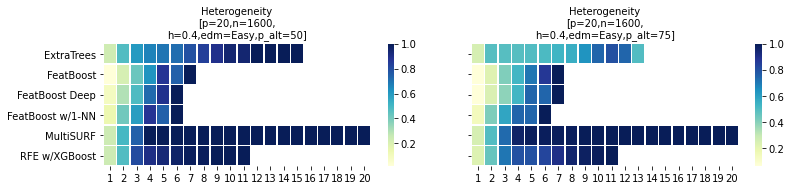

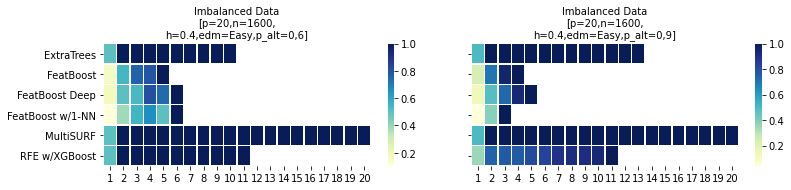

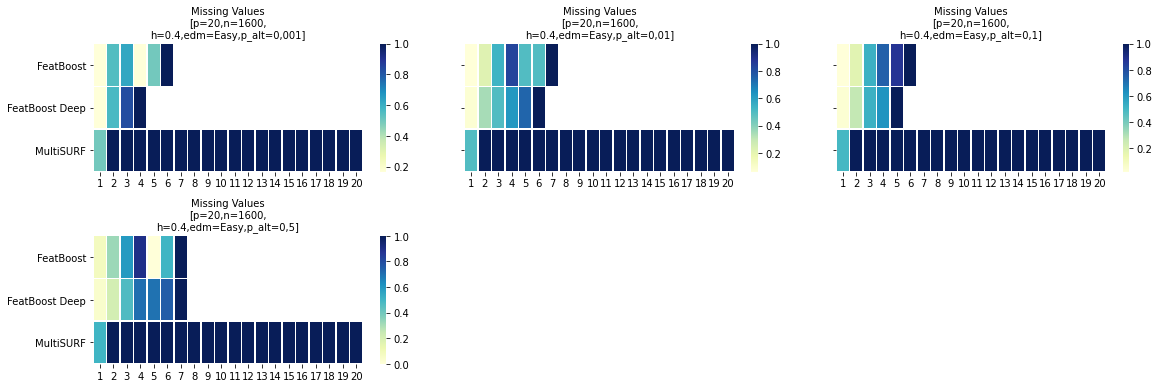

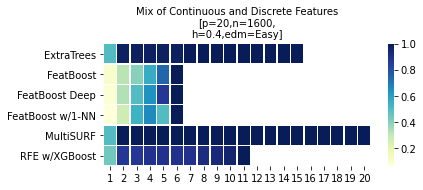

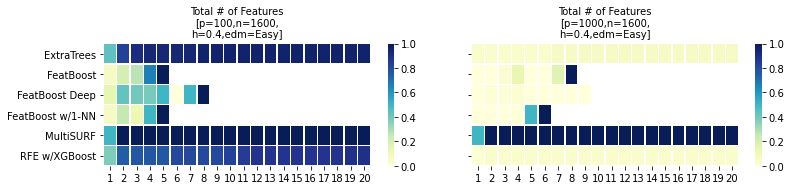

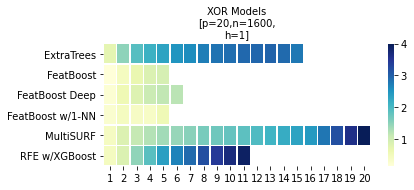

In [60]:
def draw_heatmap(*args, **kwargs):
    data = kwargs.pop('data')
    rect = pd.pivot_table(data, values='recall',\
                        index=['ranking_method'],\
                        columns=['feature_rank'])
    sns.heatmap(rect, linewidths=.5, cmap="YlGnBu")
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
    plt.yticks(rotation=0)
    plt.xticks(rotation=0)

def pltrecall(data, title):
    fg = sns.FacetGrid(data, col='description', sharex=False, col_wrap=3, size=2.75, aspect=2)
    fg.map_dataframe(draw_heatmap).set_titles("{col_name}")
    fg.fig.subplots_adjust(wspace=0.1, hspace=0.5)
    # plt.subplots_adjust(top=0.875)
    # fg.fig.suptitle(title)
    # fg.fig.tight_layout()

for name, data in subset.groupby('name'):
    pltrecall(data, name)